# Website Funnel Drop-off Analyzer

A laptop-friendly, notebook-first project using event data from an online cosmetics store. We will measure a simple **product view → add to cart → purchase** funnel by session, compare conversion over time, and inspect the largest drop-off.

> Dataset limitation: the source records product `view`, `cart`, `remove_from_cart`, and `purchase` events. It does not contain landing-page or checkout events, so this project must not label those as funnel stages. This is an observed session funnel, not a full website journey.

Dataset: [eCommerce Events History in Cosmetics Shop](https://www.kaggle.com/datasets/mkechinov/ecommerce-events-history-in-cosmetics-shop). The dataset description says rows are events and includes timestamps, event types, user IDs, and temporary session IDs. Kaggle access may require an account.

## 1. Setup
Download the CSV from Kaggle, extract it, and set `DATA_PATH` below. Start with a small number of rows to keep memory use low. The first-row sample is chronological if the source file is time-sorted, so it represents only the beginning of the dataset; later we can sample multiple date ranges.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA_PATH = Path("2019-Oct.csv")
NROWS = None

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Place the downloaded CSV here or update DATA_PATH: {DATA_PATH.resolve()}"
    )

df = pd.read_csv(
    DATA_PATH,
    nrows=NROWS,
    usecols=["event_time", "event_type", "product_id", "user_id", "user_session"]
)

print(f"Loaded {len(df):,} events from {DATA_PATH.name}")
df.head()

Loaded 4,102,283 events from 2019-Oct.csv


,event_time,event_type,product_id,user_id,user_session
0,2019-10-01 00:00:00 UTC,cart,5773203,463240011,26dd6e6e-4dac-4778-8d2c-92e149dab885
1,2019-10-01 00:00:03 UTC,cart,5773353,463240011,26dd6e6e-4dac-4778-8d2c-92e149dab885
2,2019-10-01 00:00:07 UTC,cart,5881589,429681830,49e8d843-adf3-428b-a2c3-fe8bc6a307c9
3,2019-10-01 00:00:07 UTC,cart,5723490,463240011,26dd6e6e-4dac-4778-8d2c-92e149dab885
4,2019-10-01 00:00:15 UTC,cart,5881449,429681830,49e8d843-adf3-428b-a2c3-fe8bc6a307c9


## 2. Inspect and validate the data
Check event names, missing identifiers, duplicates, and the time range before calculating metrics. Missing session IDs are excluded because they cannot be assigned to a session reliably.

In [2]:
df.info()
display(df.isna().sum().rename('missing_count').to_frame())
display(df['event_type'].value_counts(dropna=False).to_frame('events'))
print('Duplicate rows:', df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4102283 entries, 0 to 4102282
Data columns (total 5 columns):
 #   Column        Dtype 
---  ------        ----- 
 0   event_time    object
 1   event_type    object
 2   product_id    int64 
 3   user_id       int64 
 4   user_session  object
dtypes: int64(2), object(3)
memory usage: 156.5+ MB


,missing_count
event_time,0
event_type,0
product_id,0
user_id,0
user_session,637


,events
event_type,
view,1862164
cart,1232385
remove_from_cart,762110
purchase,245624


Duplicate rows: 213155


In [3]:
df["event_time"] = pd.to_datetime(
    df["event_time"], utc=True, errors="coerce"
)

df = df.dropna(
    subset=["event_time", "user_session", "event_type"]
).copy()

df["event_type"] = df["event_type"].astype(str).str.lower().str.strip()

df = df.sort_values(
    ["user_session", "event_time"], kind="stable"
)

print("Rows after cleaning:", f"{len(df):,}")
print("Time range:", df["event_time"].min(), "to", df["event_time"].max())
print("Sessions:", f"{df['user_session'].nunique():,}")
print("Event types:", sorted(df["event_type"].unique()))

Rows after cleaning: 4,101,646
Time range: 2019-10-01 00:00:00+00:00 to 2019-10-31 23:59:54+00:00
Sessions: 873,960
Event types: ['cart', 'purchase', 'remove_from_cart', 'view']


## 3. Define the funnel rule
A session reaches a stage if that event occurs **after** the prior stage in the same session: at least one `view`, followed later by `cart`, followed later by `purchase`. Sessions that start with cart or purchase do not count as reaching earlier stages. Repeated product events are allowed. This definition measures event progression; it does not prove that each carted item was the item purchased.

In [4]:
event = df["event_type"]
session_id = df["user_session"]

# A cart counts only if a view happened earlier in that session.
df["_view"] = event.eq("view")
df["_view_seen"] = df.groupby(session_id, sort=False)["_view"].cummax()

df["_cart"] = event.eq("cart") & df["_view_seen"]

# A purchase counts only if a qualifying cart happened earlier.
df["_cart_seen"] = df.groupby(session_id, sort=False)["_cart"].cummax()
df["_purchase"] = event.eq("purchase") & df["_cart_seen"]

# Keep the first timestamp at which each qualifying stage was reached.
df["_view_time"] = df["event_time"].where(df["_view"])
df["_cart_time"] = df["event_time"].where(df["_cart"])
df["_purchase_time"] = df["event_time"].where(df["_purchase"])

session = (
    df.groupby("user_session", sort=False)
      .agg(
          view=("_view", "any"),
          cart=("_cart", "any"),
          purchase=("_purchase", "any"),
          view_time=("_view_time", "min"),
          cart_time=("_cart_time", "min"),
          purchase_time=("_purchase_time", "min"),
      )
      .reset_index()
)

print("Sessions summarized:", f"{len(session):,}")
session.head()

Sessions summarized: 873,960


,user_session,view,cart,purchase,view_time,cart_time,purchase_time
0,000013d6-68a4-40cf-9452-6577dbfab515,True,True,True,2019-10-23 09:07:38+00:00,2019-10-23 09:44:43+00:00,2019-10-23 11:12:21+00:00
1,000027d7-5077-4a81-89de-ce2c4936a28f,True,False,False,2019-10-07 19:35:37+00:00,NaT,NaT
2,00002e32-16ef-4770-9ec0-36ef9d1c888f,True,False,False,2019-10-22 08:29:50+00:00,NaT,NaT
3,00003443-8504-4e24-8e86-e8e86d486826,True,True,False,2019-10-17 15:33:24+00:00,2019-10-17 15:34:08+00:00,NaT
4,0000553a-62bd-436c-86d1-1d63b1947d63,True,True,False,2019-10-08 07:47:00+00:00,2019-10-08 07:47:08+00:00,NaT


## 4. Calculate funnel counts and conversion
Step conversion is the number reaching the next stage divided by the number reaching the current stage. Overall conversion is purchases divided by sessions with a qualifying view. Always show counts with percentages.

In [5]:
stages = ["view", "cart", "purchase"]
counts = session[stages].sum().astype(int)

funnel = pd.DataFrame({"sessions": counts})
funnel["conversion_from_previous"] = [
    None,
    counts["cart"] / counts["view"] if counts["view"] else None,
    counts["purchase"] / counts["cart"] if counts["cart"] else None,
]
funnel["dropoff_from_previous"] = [
    None,
    counts["view"] - counts["cart"],
    counts["cart"] - counts["purchase"],
]

display(
    funnel.style.format({
        "conversion_from_previous": "{:.1%}",
        "dropoff_from_previous": "{:,.0f}",
    })
)

overall_conversion = counts["purchase"] / counts["view"] if counts["view"] else 0
print(f"Overall view-to-purchase conversion: {overall_conversion:.1%}")

,sessions,conversion_from_previous,dropoff_from_previous
view,826147,nan%,nan
cart,178396,21.6%,"647,751"
purchase,19414,10.9%,"158,982"


Overall view-to-purchase conversion: 2.3%


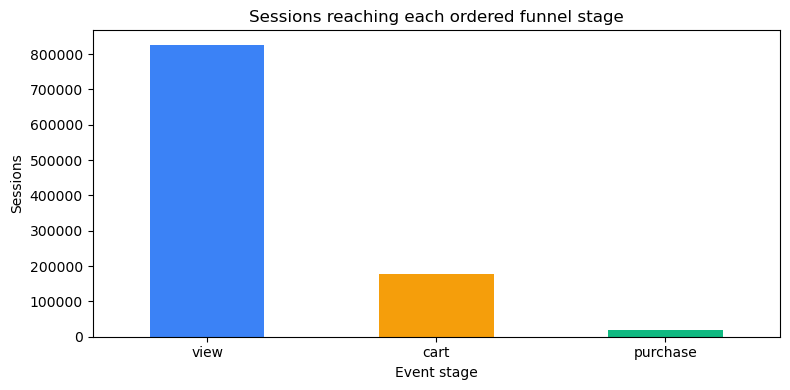

In [6]:
ax = counts.plot(kind='bar', color=['#3B82F6', '#F59E0B', '#10B981'], figsize=(8, 4))
ax.set_title('Sessions reaching each ordered funnel stage')
ax.set_ylabel('Sessions')
ax.set_xlabel('Event stage')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 5. Explore daily conversion
Daily conversion can be noisy, especially with small counts. This groups sessions by the date of their first qualifying view and reports the session counts used in each rate.

,view_sessions,cart_sessions,purchase_sessions,view_to_cart,cart_to_purchase,view_to_purchase
view_date,,,,,,
2019-10-01,27759,7747,764,27.9%,9.9%,2.8%
2019-10-02,42057,22076,754,52.5%,3.4%,1.8%
2019-10-03,24499,4713,731,19.2%,15.5%,3.0%
2019-10-04,22190,3747,622,16.9%,16.6%,2.8%
2019-10-05,21210,4515,491,21.3%,10.9%,2.3%
2019-10-06,38587,19406,602,50.3%,3.1%,1.6%
2019-10-07,36858,13505,774,36.6%,5.7%,2.1%
2019-10-08,29752,7492,711,25.2%,9.5%,2.4%
2019-10-09,28332,4461,713,15.7%,16.0%,2.5%


,view_sessions,cart_sessions,purchase_sessions
view_date,,,
2019-10-01,27759,7747,764
2019-10-02,42057,22076,754
2019-10-03,24499,4713,731
2019-10-04,22190,3747,622
2019-10-05,21210,4515,491
2019-10-06,38587,19406,602
2019-10-07,36858,13505,774
2019-10-08,29752,7492,711
2019-10-09,28332,4461,713


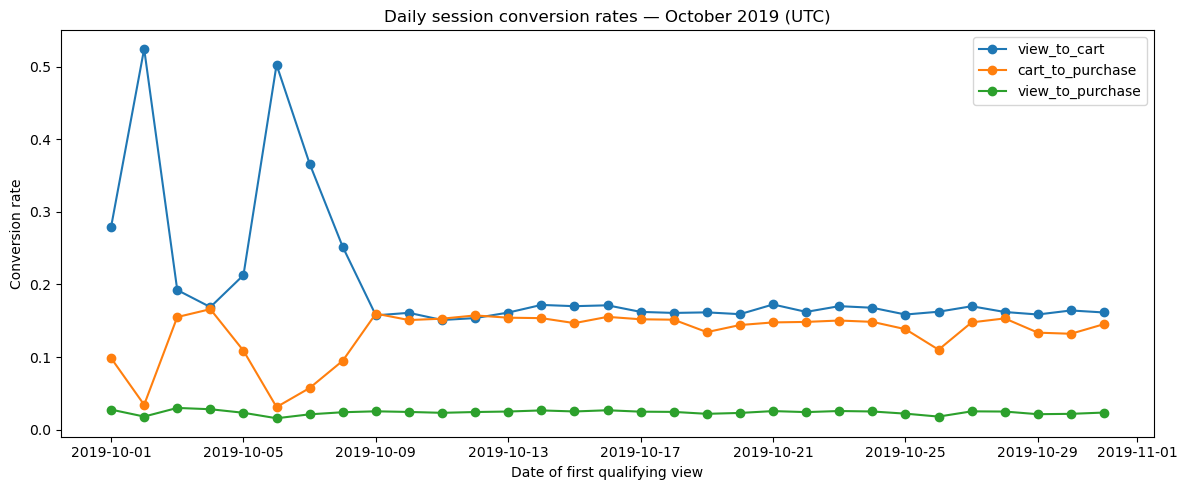

In [7]:
session["view_date"] = pd.to_datetime(
    session["view_time"], utc=True
).dt.date

daily = (
    session.dropna(subset=["view_date"])
    .groupby("view_date")
    .agg(
        view_sessions=("view", "sum"),
        cart_sessions=("cart", "sum"),
        purchase_sessions=("purchase", "sum"),
    )
)

daily["view_to_cart"] = (
    daily["cart_sessions"] / daily["view_sessions"]
)
daily["cart_to_purchase"] = (
    daily["purchase_sessions"] / daily["cart_sessions"]
)
daily["view_to_purchase"] = (
    daily["purchase_sessions"] / daily["view_sessions"]
)

display(daily.style.format({
    "view_to_cart": "{:.1%}",
    "cart_to_purchase": "{:.1%}",
    "view_to_purchase": "{:.1%}",
}))

daily[
    ["view_to_cart", "cart_to_purchase", "view_to_purchase"]
].plot(figsize=(12, 5), marker="o")

display(
    daily[["view_sessions", "cart_sessions", "purchase_sessions"]]
)

plt.title("Daily session conversion rates — October 2019 (UTC)")
plt.ylabel("Conversion rate")
plt.xlabel("Date of first qualifying view")
plt.tight_layout()
plt.show()

In [8]:
raw_daily_events = (
    df.groupby([df["event_time"].dt.date, "event_type"])
      .size()
      .unstack(fill_value=0)
)

dates_to_check = [
    pd.Timestamp("2019-10-01").date(),
    pd.Timestamp("2019-10-02").date(),
    pd.Timestamp("2019-10-03").date(),
    pd.Timestamp("2019-10-06").date(),
    pd.Timestamp("2019-10-07").date(),
]

display(raw_daily_events.loc[dates_to_check])

event_type,cart,purchase,remove_from_cart,view
event_time,,,,
2019-10-01,46910,8476,25813,61209
2019-10-02,89102,9100,26347,76497
2019-10-03,35733,8865,23299,56934
2019-10-06,81361,7265,25823,72916
2019-10-07,66942,9376,29218,75899


In [9]:
peak_session_rate_day = daily["view_to_cart"].idxmax()
peak_raw_cart_day = raw_daily_events["cart"].idxmax()

finding = (
    f"\n1. In October 2019, {counts['view']:,} sessions had a qualifying product view. "
    f"\n2. {counts['cart']:,} proceeded to cart ({counts['cart'] / counts['view']:.1%}), "
    f"\n3. and {counts['purchase']:,} proceeded to purchase "
    f"\n4. ({counts['purchase'] / counts['cart']:.1%} of cart sessions; "
    f"\n5. {overall_conversion:.1%} view-to-purchase). "
    f"\n6. The highest daily view-to-cart rate was "
    f"\n7. {daily.loc[peak_session_rate_day, 'view_to_cart']:.1%} on "
    f"\n8. {peak_session_rate_day}, from "
    f"\n9. {daily.loc[peak_session_rate_day, 'view_sessions']:,} viewed sessions. "
    f"\n10. Raw cart-event volume peaked on {peak_raw_cart_day} "
    f"\n11. ({raw_daily_events.loc[peak_raw_cart_day, 'cart']:,} events)."
)

limitation = (
    "\n1. These are observed events from one store in October 2019. "
    "\n2. The data has no campaign, device, landing-page, or checkout fields to explain "
    "\n3. why conversion varies. The funnel measures ordered session events; it does not "
    "\n4. match a purchased product to a specific cart item, and remove_from_cart does "
    "\n5. not reset funnel progress."
)

print("Finding:", finding)
print("Limitations:", limitation)

Finding: 
1. In October 2019, 826,147 sessions had a qualifying product view. 
2. 178,396 proceeded to cart (21.6%), 
3. and 19,414 proceeded to purchase 
4. (10.9% of cart sessions; 
5. 2.3% view-to-purchase). 
6. The highest daily view-to-cart rate was 
7. 52.5% on 
8. 2019-10-02, from 
9. 42,057 viewed sessions. 
10. Raw cart-event volume peaked on 2019-10-02 
11. (89,102 events).
Limitations: 
1. These are observed events from one store in October 2019. 
2. The data has no campaign, device, landing-page, or checkout fields to explain 
3. why conversion varies. The funnel measures ordered session events; it does not 
4. match a purchased product to a specific cart item, and remove_from_cart does 
5. not reset funnel progress.


## Flag unusually high daily view-to-cart rates
We’ll add a simple statistical screening rule to identify days worth investigating. It uses the interquartile range (IQR), so it’s lightweight and easy to explain. It flags unusual values; it doesn’t explain their cause.

In [10]:
dropoff_columns = {
    "view_to_cart": "view_to_cart_dropoff",
    "cart_to_purchase": "cart_to_purchase_dropoff",
}

flag_columns = []

for conversion_column, dropoff_column in dropoff_columns.items():
    daily[dropoff_column] = 1 - daily[conversion_column]

    q1 = daily[dropoff_column].quantile(0.25)
    q3 = daily[dropoff_column].quantile(0.75)
    upper_fence = q3 + 1.5 * (q3 - q1)

    flag_column = f"{dropoff_column}_flag"
    daily[flag_column] = daily[dropoff_column] > upper_fence
    flag_columns.append(flag_column)

    print(f"{dropoff_column} review threshold: {upper_fence:.1%}")

flagged_any = daily[flag_columns].any(axis=1)

display(
    daily.loc[
        flagged_any,
        [
            "view_sessions",
            "cart_sessions",
            "purchase_sessions",
            "view_to_cart_dropoff",
            "view_to_cart_dropoff_flag",
            "cart_to_purchase_dropoff",
            "cart_to_purchase_dropoff_flag",
        ],
    ]
)

view_to_cart_dropoff review threshold: 85.5%
cart_to_purchase_dropoff review threshold: 89.7%


,view_sessions,cart_sessions,purchase_sessions,view_to_cart_dropoff,view_to_cart_dropoff_flag,cart_to_purchase_dropoff,cart_to_purchase_dropoff_flag
view_date,,,,,,,
2019-10-01,27759,7747,764,0.720919,False,0.901381,True
2019-10-02,42057,22076,754,0.475093,False,0.965845,True
2019-10-06,38587,19406,602,0.497085,False,0.968979,True
2019-10-07,36858,13505,774,0.633594,False,0.942688,True
2019-10-08,29752,7492,711,0.748185,False,0.905099,True


## Compare the first eight days with the rest of October
Add and run this cell. It calculates rates from the summed session counts, which is more meaningful than taking a simple average of daily percentages.

In [11]:
daily["period"] = np.where(
    daily.index <= pd.Timestamp("2019-10-08").date(),
    "Oct 1–8",
    "Oct 9–31"
)

period_summary = (
    daily.groupby("period", observed=True)
    .agg(
        days=("view_sessions", "size"),
        view_sessions=("view_sessions", "sum"),
        cart_sessions=("cart_sessions", "sum"),
        purchase_sessions=("purchase_sessions", "sum"),
    )
)

period_summary["view_to_cart"] = (
    period_summary["cart_sessions"] / period_summary["view_sessions"]
)
period_summary["cart_to_purchase"] = (
    period_summary["purchase_sessions"] / period_summary["cart_sessions"]
)
period_summary["view_to_purchase"] = (
    period_summary["purchase_sessions"] / period_summary["view_sessions"]
)

display(period_summary.style.format({
    "view_to_cart": "{:.1%}",
    "cart_to_purchase": "{:.1%}",
    "view_to_purchase": "{:.1%}",
    "view_sessions": "{:,.0f}",
    "cart_sessions": "{:,.0f}",
    "purchase_sessions": "{:,.0f}",
}))

,days,view_sessions,cart_sessions,purchase_sessions,view_to_cart,cart_to_purchase,view_to_purchase
period,,,,,,,
Oct 1–8,8,"242,912","83,201","5,449",34.3%,6.5%,2.2%
Oct 9–31,23,"583,235","95,195","13,965",16.3%,14.7%,2.4%


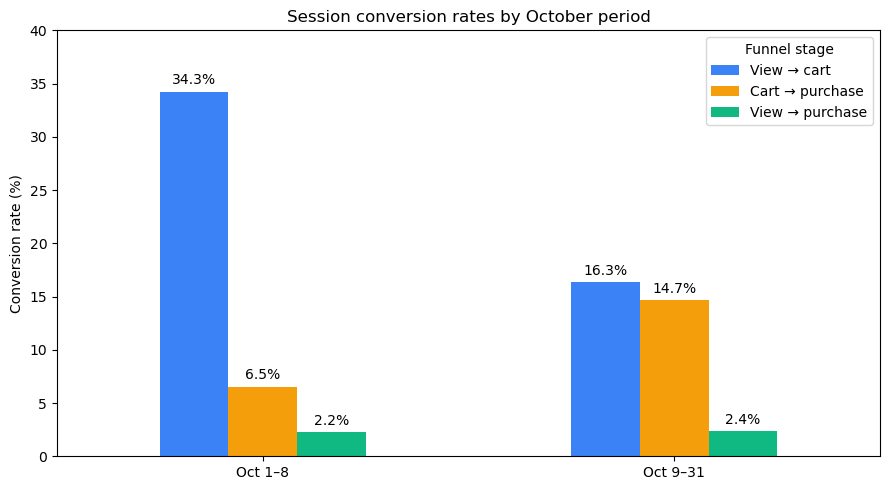

In [12]:
rate_columns = [
    "view_to_cart",
    "cart_to_purchase",
    "view_to_purchase",
]

plot_rates = period_summary[rate_columns] * 100

ax = plot_rates.plot(
    kind="bar",
    figsize=(9, 5),
    color=["#3B82F6", "#F59E0B", "#10B981"],
)

ax.set_title("Session conversion rates by October period")
ax.set_ylabel("Conversion rate (%)")
ax.set_xlabel("")
ax.set_ylim(0, 40)
ax.set_xticklabels(plot_rates.index, rotation=0)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.legend(
    ["View → cart", "Cart → purchase", "View → purchase"],
    title="Funnel stage",
)
plt.tight_layout()
plt.show()

In [13]:
early = period_summary.loc["Oct 1–8"]
later = period_summary.loc["Oct 9–31"]

finding = (
    f"\n1. In October 2019, {counts['view']:,} sessions had a qualifying product view. "
    f"\n2. {counts['cart']:,} proceeded to cart "
    f"\n3. ({counts['cart'] / counts['view']:.1%}), and "
    f"\n4. {counts['purchase']:,} proceeded to purchase "
    f"\n5. ({counts['purchase'] / counts['cart']:.1%} of cart sessions; "
    f"\n6. {overall_conversion:.1%} view-to-purchase). "
    f"\n7. Rates differed by first-view period: Oct 1–8 had "
    f"\n8. {early['view_to_cart']:.1%} view-to-cart and "
    f"\n9. {early['cart_to_purchase']:.1%} cart-to-purchase conversion, while "
    f"\n10. Oct 9–31 had {later['view_to_cart']:.1%} and "
    f"\n11. {later['cart_to_purchase']:.1%}, respectively. "
    f"\n12. Overall view-to-purchase conversion was similar "
    f"\n13. ({early['view_to_purchase']:.1%} vs {later['view_to_purchase']:.1%})."
)

limitation = (
    "\n1. This is observational event data from one store for one month. "
    "\n2. It has no campaign, device, landing-page, or checkout fields to explain "
    "\n3. the period difference. The funnel uses ordered session events; it does not "
    "\n4. match a purchase to a specific cart item, and remove_from_cart does not "
    "\n5. reset funnel progress."
)

print("Finding:", finding)
print("Limitations:", limitation)

Finding: 
1. In October 2019, 826,147 sessions had a qualifying product view. 
2. 178,396 proceeded to cart 
3. (21.6%), and 
4. 19,414 proceeded to purchase 
5. (10.9% of cart sessions; 
6. 2.3% view-to-purchase). 
7. Rates differed by first-view period: Oct 1–8 had 
8. 34.3% view-to-cart and 
9. 6.5% cart-to-purchase conversion, while 
10. Oct 9–31 had 16.3% and 
11. 14.7%, respectively. 
12. Overall view-to-purchase conversion was similar 
13. (2.2% vs 2.4%).
Limitations: 
1. This is observational event data from one store for one month. 
2. It has no campaign, device, landing-page, or checkout fields to explain 
3. the period difference. The funnel uses ordered session events; it does not 
4. match a purchase to a specific cart item, and remove_from_cart does not 
5. reset funnel progress.


In [14]:
from pathlib import Path
import shutil

app_source = Path(
    r"C:\Users\ASUS\Documents\Codex\2026-11-02\so-x20\outputs\streamlit_app\app.py"
)
requirements_source = app_source.parent / "requirements.txt"

app_target = Path.cwd() / "app.py"
requirements_target = Path.cwd() / "requirements.txt"

app_code = app_source.read_text(encoding="utf-8")
app_code = app_code.replace(
    'DATA_PATH = APP_DIR / "data" / "2019-Oct.csv"',
    f'DATA_PATH = Path(r"{Path(DATA_PATH).resolve()}")',
)

app_target.write_text(app_code, encoding="utf-8")
shutil.copy2(requirements_source, requirements_target)

print("App created at:", app_target)
print("Dataset path:", Path(DATA_PATH).resolve())

App created at: C:\Users\ASUS\Projects\Webite-Funnel-Drop-off-Analyzer\app.py
Dataset path: C:\Users\ASUS\Projects\Webite-Funnel-Drop-off-Analyzer\2019-Oct.csv


In [15]:
import subprocess
import sys
from pathlib import Path

streamlit_process = subprocess.Popen(
    [
        sys.executable,
        "-m",
        "streamlit",
        "run",
        str(Path.cwd() / "app.py"),
    ],
    cwd=Path.cwd(),
)

print("Streamlit is starting. It should open in your browser.")

Streamlit is starting. It should open in your browser.
